# Hielo v0: hielo en el subsuelo de los sitios de la Luna y Marte frente al permafrost de la Tierra

Capa para el uso **«agua, hielo y permafrost»** del plan A + D. Para cada sitio y cada región de la Tierra se calcula
**qué fracción de la zona tiene hielo cerca de la superficie** y se comparan.

| | Dato | Qué da |
|---|---|---|
| Luna | Diviner PRP (de clima_v1) | parte del sitio donde el hielo de agua sería estable bajo la superficie (polo sur) |
| Marte | SWIM (Subsurface Water Ice Mapping), consistencia con hielo en 0–1 m y 1–5 m, 60° S–60° N, 3 km | parte de la zona (25 km) compatible con hielo a menos de 5 m |
| Marte, \|lat\| ≥ 60° | supuesto: hielo cerca de la superficie (Mars Odyssey; Phoenix lo encontró a pocos cm) | 1 |
| Tierra | permafrost de Obu et al.: hemisferio norte (2019) y Antártida (2020), 1 km | probabilidad media de permafrost en la región |
| Tierra, Antártida | estaciones de COMNAP | base más cercana (km): ¿se puede ir a probar equipos? |

**Distancia de hielo** = |fracción del sitio − fracción de la región| (0 = igual). Se combina con la distancia topográfica
(`similitud_sitio_tierra_todas.csv`) para dar, a cada sitio con hielo, la región de la Tierra más parecida en hielo **y** terreno.

Incluye los dos sitios nuevos de la ficha (29 oct): **University Valley** (Goordial et al. 2016; el permafrost más parecido al
de Phoenix) y las **cuevas de hielo del Erebus** (Tebo et al. 2015; candidato, la fuente lo compara con Europa).

**Requisitos**: clima_v1 (para `prp_sitios.csv`), geologia_v0 (química de Marte, opcional) y topografia_sitios_v2.

## 1. Configuración

In [32]:
import os, re, json, glob, zipfile, shutil, datetime, unicodedata, warnings
import numpy as np, pandas as pd, requests, geopandas as gpd, rasterio
import matplotlib.pyplot as plt
from pyproj import CRS, Transformer
from shapely.geometry import shape, Point
from shapely import affinity, contains_xy
from IPython.display import display
from google.colab import drive
warnings.filterwarnings("ignore", message=".*geographic CRS.*")

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "hielo_v0"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
BRUTOS = f"{BASE}/03_datos/brutos/hielo"
CACHE = f"{BASE}/03_datos/cache_api/hielo"
PROCESADOS = f"{BASE}/03_datos/procesados"
TMP = "/content/tmp/hielo"
for d in (RES, WEB, BRUTOS, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

R_TIERRA, R_LUNA, R_MARTE = 6371.0, 1737400.0, 3396190.0
RADIO_LUNA_KM, RADIO_MARTE_KM, RADIO_ANALOGO_KM = 10, 25, 10    # las mismas zonas que en topografía y geología
LAT_HIELO_MARTE = 60                 # |lat| ≥ 60°: se supone hielo cerca de la superficie (fuera de SWIM)
UMBRAL_HIELO = 0.25                  # distancia de hielo para «parecido»
UMBRAL_CI = 0.2                      # SWIM: consistencia mínima para contar hielo (cerca de 0 = no concluyente)
TS_SIN_PERMAFROST = 3.0              # Tierra fuera de los mapas: sin permafrost si la superficie media (MODIS) supera 3 °C
CLIMA_TIERRA = f"{BASE}/04_resultados/clima_v1/clima_tierra_superficie.csv"
UMBRAL_TOPO = 0.2
MAX_PUNTOS_REGION = 4000             # puntos de muestreo por región de la Tierra
PRP = f"{BASE}/03_datos/cache_api/clima/diviner/prp_sitios.csv"
GRS_H2O = f"{BASE}/03_datos/cache_api/geologia/grs_h2o_sr_5x5.tab"
TOPO_TODAS = f"{BASE}/04_resultados/topografia_sitios_v2/similitud_sitio_tierra_todas.csv"

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

SESION = requests.Session()
SESION.headers["User-Agent"] = "Mozilla/5.0 (Hackathon NASA Space Apps; Colab)"

def descargar(urls, destino, minimo_bytes=1000, es_zip=False):
    valido = lambda p: os.path.exists(p) and os.path.getsize(p) >= minimo_bytes and (not es_zip or zipfile.is_zipfile(p))
    if valido(destino):
        return destino
    for url in urls:
        try:
            tmp = f"{TMP}/{os.path.basename(destino)}.part"
            with SESION.get(url, stream=True, timeout=900) as r:
                r.raise_for_status()
                with open(tmp, "wb") as f:
                    for trozo in r.iter_content(1 << 22):
                        f.write(trozo)
            if valido(tmp):
                shutil.copy2(tmp, destino); os.remove(tmp)
                print(f"   ✔ {os.path.basename(destino)} ({os.path.getsize(destino) / 1e6:.1f} MB)")
                return destino
            print(f"   ⚠ {url[:80]}: el archivo no es válido ({os.path.getsize(tmp) if os.path.exists(tmp) else 0:,} bytes)")
        except Exception as e:
            print(f"   ⚠ {url[:80]}: {e!r}"[:200])
    return None

def slug(t):
    return re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().lower()).strip("-")[:40]

entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
sitios = gpd.read_file(f"{BASE}/06_web/sitios_v0/sitios.geojson")
polar = gpd.read_file(f"{PROCESADOS}/sitios_luna_polar.gpkg")
print(sitios.groupby(["cuerpo", "tipo"]).size())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuerpo  tipo                     
luna    aterrizaje_planificado        1
        aterrizaje_robotico          22
        aterrizaje_tripulado          6
        region_aterrizaje_artemis     9
marte   aterrizaje_planificado        1
        aterrizaje_robotico          11
        exploration_zone             47
dtype: int64


## 2. Regiones de la Tierra: candidatas, análogos conocidos y los dos sitios nuevos
Las mismas que en topografía y geología. University Valley y las cuevas del Erebus se añaden aquí aunque todavía no estén en
`analogos.geojson` (entran ahí cuando se vuelva a ejecutar la exportación web desde la ficha).

In [33]:
EXTRA = [  # sitios nuevos de la ficha (29 oct 2026)
    {"nombre": "University Valley (Valles Secos de McMurdo)", "lat": -77.8662, "lon": 160.7324, "perfil": "marte", "verificacion": "verificada",
     "fuente": "Goordial et al. 2016, ISME J, doi:10.1038/ismej.2015.239"},
    {"nombre": "Cuevas de hielo fumarólicas del Erebus (Warren Cave)", "lat": -77.5167, "lon": 167.1647, "perfil": "marte", "verificacion": "candidato",
     "fuente": "Tebo et al. 2015, Front. Microbiol., doi:10.3389/fmicb.2015.00179"},
]

def circulo_grados(lon, lat, radio_km):
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

filas = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    gj = json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))
    for ft in gj["features"]:
        p = ft["properties"]
        filas.append({"region_id": p["id"], "perfil": cuerpo, "tipo_tierra": "region_candidata", "region": p.get("region"), "geom": shape(ft["geometry"])})
    an = json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))
    for ft in an["features"]:
        p = ft["properties"]
        ok = (p.get("tipo") in ("analogo_luna", "impacto")) if cuerpo == "luna" else (p.get("verificacion") == "verificada")
        if not ok or not ft.get("geometry"):
            continue
        lon, lat = ft["geometry"]["coordinates"][:2]
        filas.append({"region_id": f"analogo-{cuerpo}-{slug(p['nombre'])}", "perfil": cuerpo, "tipo_tierra": "analogo_conocido",
                      "region": p["nombre"], "geom": circulo_grados(lon, lat, RADIO_ANALOGO_KM)})
for e in EXTRA:
    rid = f"analogo-{e['perfil']}-{slug(e['nombre'])}"
    if rid not in {f["region_id"] for f in filas}:
        filas.append({"region_id": rid, "perfil": e["perfil"], "tipo_tierra": "analogo_conocido" if e["verificacion"] == "verificada" else "analogo_candidato",
                      "region": e["nombre"], "geom": circulo_grados(e["lon"], e["lat"], RADIO_ANALOGO_KM)})
tierra = gpd.GeoDataFrame(filas, geometry="geom", crs="EPSG:4326")
tierra["lat_c"] = tierra.geometry.centroid.y; tierra["lon_c"] = tierra.geometry.centroid.x
print(tierra.groupby(["perfil", "tipo_tierra"]).size())

perfil  tipo_tierra      
luna    analogo_conocido      7
        region_candidata     20
marte   analogo_candidato     1
        analogo_conocido      9
        region_candidata     21
dtype: int64


## 3. Descargas
- **Permafrost** (Obu et al.): probabilidad de permafrost (PERPROB, 0–1) a 1 km, hemisferio norte (2000–2016) y Antártida
  (2000–2017), desde el almacén de PANGAEA. Unos 100–300 MB en total, se guardan en `03_datos/brutos/hielo/`.
- **SWIM** (Marte): el notebook busca los GeoTIFF de consistencia con hielo en la página de productos de SWIM.
- **COMNAP**: estaciones antárticas (uso educativo y no comercial; citar COMNAP 2024).

In [34]:
PEX = {"NH": ["https://store.pangaea.de/Publications/ObuJ-etal_2018/UiO_PEX_PERPROB_5.0_20181128_2000_2016_NH.zip"],
       "ANT": ["https://store.pangaea.de/Publications/ObuJ-etal_2019/UiO_PEX_PERPROB_5.0_20181205_2000_2017_ANT.zip",
               "http://store.pangaea.de/Publications/ObuJ-etal_2019/UiO_PEX_PERPROB_5.0_20181205_2000_2017_ANT.zip"]}
RASTER_PF = {}
for zona, urls in PEX.items():
    z = descargar(urls, f"{BRUTOS}/{os.path.basename(urls[0])}", minimo_bytes=10_000, es_zip=True)   # el de la Antártida es pequeño (solo zonas sin hielo)
    if z is None:
        print(f"⚠ Permafrost {zona}: no se pudo descargar; súbelo a {BRUTOS}/ desde {urls[0]}"); continue
    destino = f"{TMP}/pex_{zona}"
    if not glob.glob(f"{destino}/**/*.tif", recursive=True):
        with zipfile.ZipFile(z) as zz:
            zz.extractall(destino)
    tif = sorted(glob.glob(f"{destino}/**/*.tif", recursive=True), key=os.path.getsize)[-1]
    ds = rasterio.open(tif)
    if ds.crs is None:
        print(f"   ⚠ {os.path.basename(tif)} no trae CRS: se supone {'EPSG:3995' if zona == 'NH' else 'EPSG:3031'}")
        ds._crs_supuesto = "EPSG:3995" if zona == "NH" else "EPSG:3031"
    RASTER_PF[zona] = ds
    print(f"Permafrost {zona}: {os.path.basename(tif)} · {ds.width}×{ds.height} · {str(ds.crs)[:40]} · {ds.dtypes[0]} · nodata {ds.nodata}"
          f" · límites {tuple(round(b) for b in ds.bounds)}")
    print("   tifs en el zip:", [os.path.basename(t) for t in glob.glob(f"{destino}/**/*.tif", recursive=True)])

PAGINA_SWIM = "https://swim.psi.edu/SWIM4MIMProducts.php"
BASE_SWIM = "https://swim.psi.edu/output/SWIM4MIM/Global/Composite/"
RASTER_SWIM = {}
try:
    html = SESION.get(PAGINA_SWIM, timeout=120).text
    enlaces = sorted(set(requests.compat.urljoin(PAGINA_SWIM, h) for h in re.findall(r'href="([^"]+\.(?:tif|tiff|zip))"', html, re.I)))
    print(f"SWIM: {len(enlaces)} enlaces .tif/.zip en la página")
except Exception as e:
    enlaces = []; print(f"   ⚠ página de SWIM: {e!r}"[:150])
for capa, patron in (("0_1", r"Ci_0_1"), ("1_5", r"Ci_1_5")):
    cand = [u for u in enlaces if re.search(patron, u) and "Composite" in u and not re.search(r"Browse", u, re.I)]
    cand += [BASE_SWIM + f"SWIM4MIM_{patron}{ext}" for ext in (".tif", "_GeoTIFF.tif", ".zip", "_GeoTIFF.zip")]
    destino = f"{BRUTOS}/swim_ci_{capa}" + (".zip" if cand[0].lower().endswith(".zip") else ".tif")
    ruta = None
    for u in cand:
        ruta = descargar([u], f"{BRUTOS}/swim_ci_{capa}" + (".zip" if u.lower().endswith(".zip") else ".tif"), minimo_bytes=100_000,
                         es_zip=u.lower().endswith(".zip"))
        if ruta:
            break
    if ruta is None:
        print(f"⚠ SWIM Ci {capa}: no encontrado. Descárgalo (GeoTIFF) de {PAGINA_SWIM} y súbelo como {BRUTOS}/swim_ci_{capa}.tif"); continue
    if ruta.endswith(".zip"):
        d = f"{TMP}/swim_{capa}"
        with zipfile.ZipFile(ruta) as zz:
            zz.extractall(d)
        ruta = sorted(glob.glob(f"{d}/**/*.tif*", recursive=True), key=os.path.getsize)[-1]
    RASTER_SWIM[capa] = rasterio.open(ruta)
    print(f"SWIM Ci {capa}: {RASTER_SWIM[capa].width}×{RASTER_SWIM[capa].height} · {str(RASTER_SWIM[capa].crs)[:50]}")

URL_COMNAP = ["https://raw.githubusercontent.com/PolarGeospatialCenter/comnap-antarctic-facilities/master/dist/csv/COMNAP_Antarctic_Facilities_Master.csv"]
ruta = descargar(URL_COMNAP, f"{BRUTOS}/COMNAP_Antarctic_Facilities_Master.csv", minimo_bytes=5_000)
bases = pd.read_csv(ruta, encoding="utf-8-sig")
bases = bases[bases.Status.eq("Open")].rename(columns={"Latitude (DD)": "lat", "Longitude (DD)": "lon"})
print(f"COMNAP: {len(bases)} instalaciones abiertas · {bases.Type.value_counts().to_dict()}")

Permafrost NH: UiO_PEX_PERPROB_5.0_20181128_2000_2016_NH.tif · 22425×21141 · EPSG:3995 · float32 · nodata -3.4028230607370965e+38 · límites (-10389573, -10389753, 10390002, 9200036)
   tifs en el zip: ['UiO_PEX_PERPROB_5.0_20181128_2000_2016_NH.tif']
Permafrost ANT: UiO_PEX_PERPROB_5.0_20181205_2000_2017_ANT.tif · 9888×8678 · EPSG:3031 · float32 · nodata -1.0 · límites (-3489497, -2277458, 5672975, 5763798)
   tifs en el zip: ['UiO_PEX_PERPROB_5.0_20181205_2000_2017_ANT.tif']
SWIM: 0 enlaces .tif/.zip en la página
SWIM Ci 0_1: 7200×2400 · ESRI:103885
SWIM Ci 1_5: 7200×2400 · ESRI:103885
COMNAP: 103 instalaciones abiertas · {'Station': 74, 'Camp': 9, 'Refuge': 7, 'Airfield Camp': 7, 'Laboratory': 3, 'Depot': 3}


## 4. Tierra: probabilidad de permafrost por región
Rejilla de puntos dentro de cada región (hasta 4000), leídos en los dos mapas. Si ningún punto cae en los mapas: 0 si la
superficie media (MODIS, clima_v1) pasa de 3 °C o si es tropical; si no, sin dato. Antes se comprueban los mapas en puntos
conocidos con permafrost (University Valley, Valles Secos, isla Devon).

In [35]:
def puntos_en(geom, n_max=MAX_PUNTOS_REGION):
    x0, y0, x1, y1 = geom.bounds
    area = max(geom.area, 1e-9)
    paso = max(np.sqrt(area / n_max), 0.005)                  # ≥ ~0,5 km
    xx, yy = np.meshgrid(np.arange(x0 + paso / 2, x1, paso), np.arange(y0 + paso / 2, y1, paso))
    ok = contains_xy(geom, xx, yy)
    if not ok.any():
        c = geom.representative_point(); return np.array([c.x]), np.array([c.y])
    return xx[ok], yy[ok]

def leer_raster(ds, lon, lat, geo_crs="EPSG:4326"):
    destino = ds.crs if ds.crs is not None else getattr(ds, "_crs_supuesto", None)
    x, y = Transformer.from_crs(geo_crs, destino, always_xy=True).transform(lon, lat)
    v = np.full(len(lon), np.nan)
    dentro = (np.isfinite(x) & np.isfinite(y) & (x > ds.bounds.left) & (x < ds.bounds.right) & (y > ds.bounds.bottom) & (y < ds.bounds.top))
    if dentro.any():
        s = np.array([a[0] for a in ds.sample(zip(x[dentro], y[dentro]))], dtype=float)
        if ds.nodata is not None:
            s[s == ds.nodata] = np.nan
        s[(s < -1e3) | (s > 1e3)] = np.nan
        v[dentro] = s
    return v

# Comprobación: valores de los mapas en puntos conocidos (deberían tener permafrost)
PRUEBA = {"University Valley": (160.7324, -77.8662), "Valles Secos (Wright)": (161.6, -77.5), "Isla Devon": (-89.87, 75.43)}
for zona, ds in RASTER_PF.items():
    for nombre, (lo_, la_) in PRUEBA.items():
        lo_v, la_v = np.array([lo_ + d for d in (-0.2, 0, 0.2) for _ in range(3)]), np.array([la_ + d for _ in range(3) for d in (-0.05, 0, 0.05)])
        v = leer_raster(ds, lo_v, la_v)
        if (la_ < 0) == (zona == "ANT"):
            print(f"   prueba {zona} · {nombre}: {np.round(v, 2).tolist()}")

clima_t = pd.read_csv(CLIMA_TIERRA)[["region_id", "ts_media"]] if os.path.exists(CLIMA_TIERRA) else pd.DataFrame(columns=["region_id", "ts_media"])
ts_media = dict(zip(clima_t.region_id, clima_t.ts_media))

filas = []
for r in tierra.itertuples():
    lon, lat = puntos_en(r.geom)
    vals = np.full(len(lon), np.nan)
    for ds in RASTER_PF.values():
        v = leer_raster(ds, lon, lat)
        vals = np.where(np.isfinite(v), v, vals)
    ok = np.isfinite(vals)
    if ok.any():
        f, fuente = float(np.clip(vals[ok], 0, 1).mean()), "Obu et al. (PERPROB)"
    elif pd.notna(ts_media.get(r.region_id)) and ts_media[r.region_id] > TS_SIN_PERMAFROST:
        f, fuente = 0.0, f"fuera de los mapas; superficie media {ts_media[r.region_id]:.0f} °C: sin permafrost"
    elif abs(r.lat_c) < 23.5:
        f, fuente = 0.0, "trópico: sin permafrost (supuesto)"
    else:
        f, fuente = np.nan, "fuera de los mapas de permafrost"
    filas.append({"region_id": r.region_id, "f_permafrost": None if np.isnan(f) else round(f, 3), "cobertura_mapa": round(float(ok.mean()), 2),
                  "fuente_hielo": fuente, "n_puntos": len(lon)})
pf = pd.DataFrame(filas)
tierra = tierra.merge(pf, on="region_id")

def km_entre(lat1, lon1, lat2, lon2, R=R_TIERRA):
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

for k in ("base_cercana", "base_operador", "base_tipo", "base_temporada", "base_km"):
    tierra[k] = None
for i, r in tierra[tierra.lat_c < -55].iterrows():
    d = km_entre(r.lat_c, r.lon_c, bases.lat.values, bases.lon.values)
    j = int(np.argmin(d)); b = bases.iloc[j]
    tierra.loc[i, ["base_cercana", "base_operador", "base_tipo", "base_temporada", "base_km"]] = \
        [b["English Name"], b["Operator (primary)"], b["Type"], b["Seasonality"], round(float(d[j]), 1)]
cols = ["region", "perfil", "tipo_tierra", "f_permafrost", "cobertura_mapa", "fuente_hielo", "base_cercana", "base_km"]
display(tierra.sort_values("f_permafrost", ascending=False)[cols].head(25))
print(tierra.fuente_hielo.value_counts())

   prueba NH · Isla Devon: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
   prueba ANT · University Valley: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, nan, 1.0, 1.0]
   prueba ANT · Valles Secos (Wright): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


,region,perfil,tipo_tierra,f_permafrost,cobertura_mapa,fuente_hielo,base_cercana,base_km
52,Valles Secos de McMurdo,marte,analogo_conocido,1.000,1.00,Obu et al. (PERPROB),Marble Point Refueling Facility,56.8
50,Isla Devon (Haughton-Mars Project),marte,analogo_conocido,1.000,1.00,Obu et al. (PERPROB),None,None
34,"Nunavut, Canadá",marte,region_candidata,1.000,0.70,Obu et al. (PERPROB),None,None
33,"Nunavut, Canadá",marte,region_candidata,1.000,0.87,Obu et al. (PERPROB),None,None
31,Groenlandia,marte,region_candidata,1.000,0.70,Obu et al. (PERPROB),None,None
32,Groenlandia,marte,region_candidata,1.000,0.81,Obu et al. (PERPROB),None,None
30,"Nunavut, Canadá",marte,region_candidata,1.000,0.77,Obu et al. (PERPROB),None,None
29,"Nunavut, Canadá",marte,region_candidata,1.000,0.66,Obu et al. (PERPROB),None,None
28,"Nunavut, Canadá",marte,region_candidata,1.000,0.71,Obu et al. (PERPROB),None,None
27,Groenlandia,marte,region_candidata,1.000,0.65,Obu et al. (PERPROB),None,None


fuente_hielo
Obu et al. (PERPROB)                                          34
fuera de los mapas; superficie media 32 °C: sin permafrost     5
fuera de los mapas; superficie media 37 °C: sin permafrost     2
fuera de los mapas; superficie media 33 °C: sin permafrost     2
fuera de los mapas; superficie media 30 °C: sin permafrost     2
fuera de los mapas; superficie media 28 °C: sin permafrost     2
fuera de los mapas; superficie media 27 °C: sin permafrost     2
fuera de los mapas; superficie media 25 °C: sin permafrost     2
fuera de los mapas; superficie media 34 °C: sin permafrost     2
fuera de los mapas; superficie media 38 °C: sin permafrost     1
fuera de los mapas; superficie media 36 °C: sin permafrost     1
fuera de los mapas; superficie media 31 °C: sin permafrost     1
fuera de los mapas; superficie media 14 °C: sin permafrost     1
fuera de los mapas; superficie media 35 °C: sin permafrost     1
Name: count, dtype: int64


## 5. Luna y Marte: hielo en cada sitio
- **Luna**: `frac_hielo_estable` de Diviner PRP (clima_v1). Fuera del polo sur, 0: lejos de las trampas frías polares el hielo no
  es estable cerca de la superficie.
- **Marte**: puntos en un círculo de 25 km; fracción de puntos con consistencia ≥ 0,2 en 0–1 m **o** en 1–5 m (SWIM; los valores
  cercanos a 0 no son concluyentes).
  En |lat| ≥ 60° se supone hielo (1). El agua equivalente de Mars Odyssey (GRS) se guarda como información.

In [36]:
prp = pd.read_csv(PRP) if os.path.exists(PRP) else pd.DataFrame(columns=["id", "frac_hielo_estable", "hielo_prof_mediana"])
if not os.path.exists(PRP):
    print("⚠ Falta prp_sitios.csv: ejecuta clima_v1 (sección 6b). La Luna queda sin hielo polar.")
GEO_MARTE = CRS.from_proj4(f"+proj=longlat +R={R_MARTE} +no_defs")

def puntos_circulo(lon, lat, radio_km, R, n=12):
    aeqd = CRS.from_proj4(f"+proj=aeqd +lat_0={lat} +lon_0={lon} +R={R} +units=m +no_defs")
    paso = radio_km * 1000 / n
    v = np.arange(-radio_km * 1000, radio_km * 1000 + paso, paso)
    xx, yy = np.meshgrid(v, v); ok = np.hypot(xx, yy) <= radio_km * 1000
    lo, la = Transformer.from_crs(aeqd, CRS.from_proj4(f"+proj=longlat +R={R} +no_defs"), always_xy=True).transform(xx[ok], yy[ok])
    return np.asarray(lo), np.asarray(la)

def swim_en(lon, lat):
    out = {}
    for capa, ds in RASTER_SWIM.items():
        c = CRS.from_user_input(ds.crs) if ds.crs else GEO_MARTE
        geo = c.geodetic_crs if not c.is_geographic else c
        lon_ = np.where(lon < 0, lon + 360, lon) if ds.bounds.right > 180 else lon
        v = leer_raster(ds, lon_, lat, geo)
        v[(v <= -29) | (v < -1.01) | (v > 1.01)] = np.nan            # sin dato = -30
        out[capa] = v
    return out

grs = None
if os.path.exists(GRS_H2O):
    grs = pd.read_csv(GRS_H2O, sep=r"\s+", header=None, usecols=range(3), names=["lat", "lon", "h2o"])
    grs.loc[grs.h2o > 9999, "h2o"] = np.nan; grs["lon"] = grs.lon % 360

filas = []
for r in sitios.itertuples():
    lon, lat = (r.geometry.centroid.x, r.geometry.centroid.y)
    fila = {"id": r.id, "nombre": r.nombre, "cuerpo": r.cuerpo, "tipo": r.tipo, "lat": round(lat, 3), "lon": round(lon, 3)}
    if r.cuerpo == "luna":
        p = prp[prp.id == r.id]
        if len(p):
            fila.update(f_hielo=round(float(p.frac_hielo_estable.iloc[0]), 3), hielo_prof=p.hielo_prof_mediana.iloc[0],
                        fuente_hielo="Diviner PRP (hielo estable)")
        else:
            fila.update(f_hielo=0.0, fuente_hielo="fuera del polo sur: sin hielo estable cerca de la superficie")
    else:
        if abs(lat) >= LAT_HIELO_MARTE:
            fila.update(f_hielo=1.0, fuente_hielo=f"|lat| ≥ {LAT_HIELO_MARTE}°: hielo cerca de la superficie (supuesto)")
        elif RASTER_SWIM:
            plo, pla = puntos_circulo(lon, lat, RADIO_MARTE_KM, R_MARTE)
            s = swim_en(plo, pla)
            m = np.nanmax(np.vstack(list(s.values())), axis=0) if s else np.array([np.nan])
            ok = np.isfinite(m)
            fila.update(f_hielo=round(float((m[ok] >= UMBRAL_CI).mean()), 3) if ok.any() else None,
                        ci_0_1=round(float(np.nanmean(s["0_1"])), 3) if "0_1" in s and np.isfinite(s["0_1"]).any() else None,
                        ci_1_5=round(float(np.nanmean(s["1_5"])), 3) if "1_5" in s and np.isfinite(s["1_5"]).any() else None,
                        fuente_hielo=f"SWIM (consistencia ≥ {UMBRAL_CI} a menos de 5 m)" if ok.any() else "SWIM sin dato")
        else:
            fila.update(f_hielo=None, fuente_hielo="SWIM no descargado")
        if grs is not None:
            d = np.hypot(grs.lat - lat, ((grs.lon - lon % 360 + 180) % 360) - 180)
            v = grs.h2o.iloc[int(np.argmin(d))]
            fila["h2o_grs_pct"] = None if pd.isna(v) else round(float(v), 2)
    filas.append(fila)
hielo_sit = pd.DataFrame(filas)
display(hielo_sit[hielo_sit.f_hielo.fillna(0) > 0].sort_values(["cuerpo", "f_hielo"], ascending=[True, False]))
print(hielo_sit.groupby("cuerpo").fuente_hielo.value_counts())

,id,nombre,cuerpo,tipo,lat,lon,f_hielo,hielo_prof,fuente_hielo,ci_0_1,ci_1_5,h2o_grs_pct
34,aterrizaje-im-1-odysseus,IM-1 Odysseus,luna,aterrizaje_robotico,-84.900,12.900,0.968,0.055220,Diviner PRP (hielo estable),NaN,NaN,NaN
1,artemis-haworth,Haworth,luna,region_aterrizaje_artemis,-86.745,-22.852,0.615,0.125045,Diviner PRP (hielo estable),NaN,NaN,NaN
8,artemis-slater-plain,Slater Plain,luna,region_aterrizaje_artemis,-87.152,125.570,0.541,0.035590,Diviner PRP (hielo estable),NaN,NaN,NaN
4,artemis-mons-mouton,Mons Mouton,luna,region_aterrizaje_artemis,-85.422,31.755,0.465,0.251425,Diviner PRP (hielo estable),NaN,NaN,NaN
36,aterrizaje-im-2-athena,IM-2 Athena,luna,aterrizaje_robotico,-84.791,29.196,0.453,0.152215,Diviner PRP (hielo estable),NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
76,ez-arabia-terra,Arabia Terra,marte,exploration_zone,0.400,-8.300,0.027,NaN,SWIM (consistencia ≥ 0.2 a menos de 5 m),-0.004,0.010,5.46
41,aterrizaje-spirit-mer-a,Spirit (MER-A),marte,aterrizaje_robotico,-14.568,175.473,0.023,NaN,SWIM (consistencia ≥ 0.2 a menos de 5 m),0.067,-0.147,7.34
71,ez-cerberus,Cerberus,marte,exploration_zone,10.000,162.000,0.020,NaN,SWIM (consistencia ≥ 0.2 a menos de 5 m),-0.003,-0.019,5.15
67,ez-hypanis-delta,Hypanis Delta,marte,exploration_zone,11.700,-45.300,0.016,NaN,SWIM (consistencia ≥ 0.2 a menos de 5 m),-0.155,-0.129,3.71


cuerpo  fuente_hielo                                                
luna    fuera del polo sur: sin hielo estable cerca de la superficie    26
        Diviner PRP (hielo estable)                                     12
marte   SWIM (consistencia ≥ 0.2 a menos de 5 m)                        58
        |lat| ≥ 60°: hielo cerca de la superficie (supuesto)             1
Name: count, dtype: int64


## 6. Comparación: hielo, y hielo + terreno
Para cada sitio y cada región de la Tierra: `d_hielo` = |f_sitio − f_región|. Se cruza con la distancia topográfica
(los dos perfiles). Para los sitios **con hielo** (f ≥ 0,2) se busca la región más parecida en hielo y en terreno
(media de las dos) entre las regiones **con permafrost** (f ≥ 0,2): las que no tienen hielo no valen como análogo de hielo.

In [37]:
T = tierra[["region_id", "region", "perfil", "tipo_tierra", "f_permafrost", "base_cercana", "base_km"]]
S = hielo_sit[["id", "nombre", "cuerpo", "tipo", "f_hielo"]]
pares = S.merge(T, how="cross")
pares["d_hielo"] = (pares.f_hielo - pares.f_permafrost).abs().round(3)
if os.path.exists(TOPO_TODAS):
    topo = pd.read_csv(TOPO_TODAS)[["sitio_id", "region_id", "distancia"]].rename(columns={"sitio_id": "id", "distancia": "d_topo"})
    pares = pares.merge(topo, on=["id", "region_id"], how="left")
else:
    print("⚠ Falta similitud_sitio_tierra_todas.csv (topografia_sitios_v2, versión nueva): sin combinación con el terreno")
    pares["d_topo"] = np.nan
pares["d_hielo_topo"] = ((pares.d_hielo + pares.d_topo) / 2).round(3)
pares.to_csv(f"{RES}/similitud_hielo.csv", index=False)

con_hielo = pares[(pares.f_hielo >= 0.2) & (pares.f_permafrost >= 0.2)]
mejor_h = con_hielo.dropna(subset=["d_hielo"]).sort_values("d_hielo").drop_duplicates("id").set_index("id")   # no first(): rellenaría vacíos con otras filas
mejor_ht = con_hielo.dropna(subset=["d_hielo_topo"]).sort_values("d_hielo_topo").drop_duplicates("id").set_index("id")   # no first(): rellenaría vacíos con otras filas
res = (hielo_sit.merge(mejor_h[["region", "f_permafrost", "d_hielo"]].add_suffix("_h"), left_on="id", right_index=True, how="left")
                .merge(mejor_ht[["region", "perfil", "f_permafrost", "d_hielo", "d_topo", "d_hielo_topo", "base_cercana", "base_km"]].add_suffix("_ht"),
                       left_on="id", right_index=True, how="left"))
res["analogo_hielo_terreno"] = np.where((res.d_hielo_ht <= UMBRAL_HIELO) & (res.d_topo_ht <= UMBRAL_TOPO), "Sí",
                                        np.where(res.f_hielo.fillna(0) >= 0.2, "No", "—"))
res.to_csv(f"{RES}/hielo_sitios.csv", index=False)
tierra.drop(columns="geom").to_csv(f"{RES}/hielo_tierra.csv", index=False)

cols = ["nombre", "tipo", "f_hielo", "fuente_hielo", "region_ht", "f_permafrost_ht", "d_hielo_ht", "d_topo_ht", "base_cercana_ht", "base_km_ht", "analogo_hielo_terreno"]
for cuerpo in ["luna", "marte"]:
    d = res[(res.cuerpo == cuerpo) & (res.f_hielo.fillna(0) >= 0.2)].sort_values("d_hielo_topo_ht")
    print(f"{cuerpo.capitalize()}: {len(d)} sitios con hielo (f ≥ 0,2)"); display(d[cols])
print(res.groupby("cuerpo").analogo_hielo_terreno.value_counts())

Luna: 11 sitios con hielo (f ≥ 0,2)


,nombre,tipo,f_hielo,fuente_hielo,region_ht,f_permafrost_ht,d_hielo_ht,d_topo_ht,base_cercana_ht,base_km_ht,analogo_hielo_terreno
34,IM-1 Odysseus,aterrizaje_robotico,0.968,Diviner PRP (hielo estable),Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),1.000,0.032,0.142,None,None,Sí
36,IM-2 Athena,aterrizaje_robotico,0.453,Diviner PRP (hielo estable),"Askja, Islandia",0.447,0.006,0.196,None,None,Sí
4,Mons Mouton,region_aterrizaje_artemis,0.465,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.059,0.249,None,None,No
5,Nobile Rim 1,region_aterrizaje_artemis,0.353,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.171,0.143,None,None,Sí
8,Slater Plain,region_aterrizaje_artemis,0.541,Diviner PRP (hielo estable),"Askja, Islandia",0.447,0.094,0.330,None,None,No
2,Malapert Massif,region_aterrizaje_artemis,0.210,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.314,0.125,None,None,No
6,Nobile Rim 2,region_aterrizaje_artemis,0.337,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.187,0.261,None,None,No
1,Haworth,region_aterrizaje_artemis,0.615,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.091,0.359,None,None,No
0,Peak Near Cabeus B,region_aterrizaje_artemis,0.292,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.232,0.224,None,None,No
7,de Gerlache Rim 2,region_aterrizaje_artemis,0.262,Diviner PRP (hielo estable),"Provincia de Alto Badajshán, Tayikistán",0.524,0.262,0.257,None,None,No


Marte: 24 sitios con hielo (f ≥ 0,2)


,nombre,tipo,f_hielo,fuente_hielo,region_ht,f_permafrost_ht,d_hielo_ht,d_topo_ht,base_cercana_ht,base_km_ht,analogo_hielo_terreno
83,Deuteronilus Mensae 2,exploration_zone,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),Groenlandia,1.000,0.000,0.057,None,None,Sí
92,Protonilus mensae,exploration_zone,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),Groenlandia,1.000,0.000,0.062,None,None,Sí
81,E. Hellas,exploration_zone,0.995,SWIM (consistencia ≥ 0.2 a menos de 5 m),Groenlandia,1.000,0.005,0.095,None,None,Sí
80,Deuteronilus Mensae,exploration_zone,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),Groenlandia,1.000,0.000,0.100,None,None,Sí
72,S. Nectaris Fossae,exploration_zone,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),Groenlandia,1.000,0.000,0.109,None,None,Sí
39,Viking 2,aterrizaje_robotico,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),Isla Devon (Haughton-Mars Project),1.000,0.000,0.143,None,None,Sí
50,E. Melas Chasma,exploration_zone,0.206,SWIM (consistencia ≥ 0.2 a menos de 5 m),Islandia,0.216,0.010,0.139,None,None,Sí
82,E. Hellas 2,exploration_zone,0.973,SWIM (consistencia ≥ 0.2 a menos de 5 m),"Nunavut, Canadá",1.000,0.027,0.123,None,None,Sí
84,Ismenius Cavus,exploration_zone,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),"Nunavut, Canadá",1.000,0.000,0.162,None,None,Sí
94,Copernicus Crater,exploration_zone,1.000,SWIM (consistencia ≥ 0.2 a menos de 5 m),Groenlandia,1.000,0.000,0.168,None,None,Sí


cuerpo  analogo_hielo_terreno
luna    —                        27
        No                        8
        Sí                        3
marte   —                        35
        Sí                       13
        No                       11
Name: count, dtype: int64


### 6.1 Antártida: análogos y bases cercanas

In [38]:
ant = tierra[tierra.lat_c < -55].sort_values("base_km")
display(ant[["region", "tipo_tierra", "f_permafrost", "fuente_hielo", "base_cercana", "base_operador", "base_temporada", "base_km"]])
uv = pares[pares.region.str.contains("University Valley", na=False) & (pares.f_hielo >= 0.2)].sort_values("d_hielo_topo")
print("Sitios con hielo más parecidos a University Valley (hielo + terreno):")
display(uv[["nombre", "cuerpo", "f_hielo", "f_permafrost", "d_hielo", "d_topo", "d_hielo_topo"]].head(10))

,region,tipo_tierra,f_permafrost,fuente_hielo,base_cercana,base_operador,base_temporada,base_km
57,Cuevas de hielo fumarólicas del Erebus (Warren...,analogo_candidato,1.0,Obu et al. (PERPROB),Scott Base,New Zealand,Year-Round,38.2
52,Valles Secos de McMurdo,analogo_conocido,1.0,Obu et al. (PERPROB),Marble Point Refueling Facility,United States,Seasonal,56.8
56,University Valley (Valles Secos de McMurdo),analogo_conocido,1.0,Obu et al. (PERPROB),Marble Point Refueling Facility,United States,Seasonal,88.1


Sitios con hielo más parecidos a University Valley (hielo + terreno):


,nombre,cuerpo,f_hielo,f_permafrost,d_hielo,d_topo,d_hielo_topo
56,Peak Near Cabeus B,luna,0.292,1.0,0.708,NaN,NaN
114,Haworth,luna,0.615,1.0,0.385,NaN,NaN
172,Malapert Massif,luna,0.210,1.0,0.790,NaN,NaN
288,Mons Mouton,luna,0.465,1.0,0.535,NaN,NaN
346,Nobile Rim 1,luna,0.353,1.0,0.647,NaN,NaN
404,Nobile Rim 2,luna,0.337,1.0,0.663,NaN,NaN
462,de Gerlache Rim 2,luna,0.262,1.0,0.738,NaN,NaN
520,Slater Plain,luna,0.541,1.0,0.459,NaN,NaN
2028,IM-1 Odysseus,luna,0.968,1.0,0.032,NaN,NaN
2144,IM-2 Athena,luna,0.453,1.0,0.547,NaN,NaN


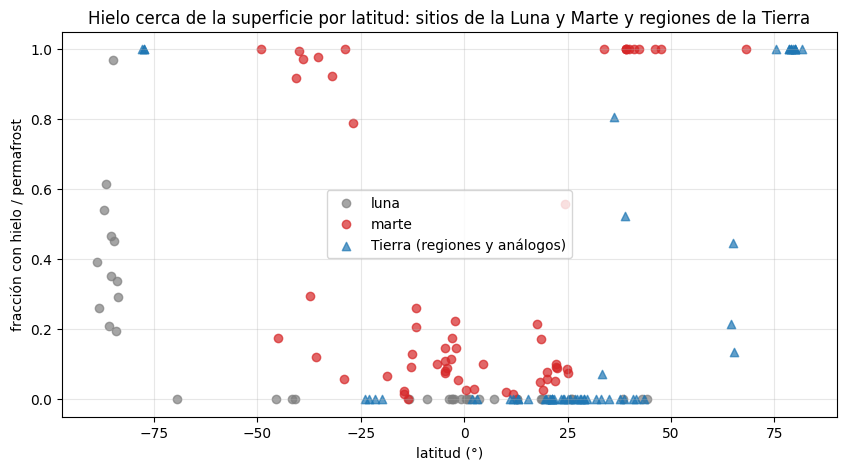

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
for cuerpo, color in (("luna", "tab:gray"), ("marte", "tab:red")):
    d = res[res.cuerpo == cuerpo].dropna(subset=["f_hielo"])
    ax.scatter(d.lat, d.f_hielo, c=color, label=cuerpo, alpha=0.7)
t = tierra.dropna(subset=["f_permafrost"])
ax.scatter(t.lat_c, t.f_permafrost, c="tab:blue", marker="^", label="Tierra (regiones y análogos)", alpha=0.7)
ax.set_xlabel("latitud (°)"); ax.set_ylabel("fracción con hielo / permafrost"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Hielo cerca de la superficie por latitud: sitios de la Luna y Marte y regiones de la Tierra"); plt.show()

## 7. Capa para la web y registro

In [40]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if not np.isfinite(v) else round(float(v), 3)
    if isinstance(v, np.integer): return int(v)
    if isinstance(v, np.bool_): return bool(v)
    return v

top5 = (pares[(pares.f_hielo >= 0.2) & (pares.f_permafrost >= 0.2)].dropna(subset=["d_hielo_topo"])
        .sort_values("d_hielo_topo").groupby("id").head(5))
salida = {"version": VERSION,
          "unidades": {"f_hielo": "fracción del sitio con hielo cerca de la superficie (0–1)",
                       "f_permafrost": "probabilidad media de permafrost en la región (0–1)",
                       "d_hielo": "|f_sitio − f_región|", "d_hielo_topo": "media de d_hielo y la distancia topográfica",
                       "base_km": "distancia a la estación antártica abierta más cercana (COMNAP)"},
          "umbrales": {"hielo": UMBRAL_HIELO, "topografia": UMBRAL_TOPO},
          "sitios": {r["id"]: {**{k: limpio(v) for k, v in r.items() if k != "id"},
                               "top5_tierra": [{k: limpio(v) for k, v in p.items() if k in ("region_id", "region", "perfil", "f_permafrost", "d_hielo",
                                                                                            "d_topo", "d_hielo_topo", "base_cercana", "base_km")}
                                               for p in top5[top5.id == r["id"]].to_dict("records")]}
                     for r in res.to_dict("records")},
          "tierra": {r["region_id"]: {k: limpio(v) for k, v in r.items() if k not in ("region_id", "geom")}
                     for r in tierra.drop(columns="geom").to_dict("records")},
          "nota": "unir con 06_web/sitios_v0/sitios.geojson por id; region_id como en topografia_v2"}
json.dump(salida, open(f"{WEB}/hielo.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["hielo"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/hielo.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

con = lambda c: res[(res.cuerpo == c) & (res.f_hielo.fillna(0) >= 0.2)]
registro = {"version": VERSION, "fecha": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="minutes"),
            "fuentes": {"permafrost_nh": PEX["NH"][0], "permafrost_ant": PEX["ANT"][0], "swim": PAGINA_SWIM,
                        "swim_capas": sorted(RASTER_SWIM), "comnap": URL_COMNAP[0], "luna": "Diviner PRP (clima_v1)"},
            "parametros": {"umbral_ci_swim": UMBRAL_CI, "ts_sin_permafrost": TS_SIN_PERMAFROST, "radio_marte_km": RADIO_MARTE_KM, "radio_analogo_km": RADIO_ANALOGO_KM, "lat_hielo_marte": LAT_HIELO_MARTE,
                           "umbral_hielo": UMBRAL_HIELO, "umbral_topo": UMBRAL_TOPO},
            "metricas": {"luna_sitios_con_hielo": len(con("luna")), "marte_sitios_con_hielo": len(con("marte")),
                         "luna_analogo_hielo_terreno": int((con("luna").analogo_hielo_terreno == "Sí").sum()),
                         "marte_analogo_hielo_terreno": int((con("marte").analogo_hielo_terreno == "Sí").sum()),
                         "regiones_tierra_con_permafrost": int((tierra.f_permafrost >= 0.2).sum()),
                         "regiones_tierra_sin_dato": int(tierra.f_permafrost.isna().sum())},
            "limitaciones": ["en la Luna el hielo es de un modelo térmico (PRP), no una detección directa",
                             "en Marte, por encima de 60° se supone hielo sin medirlo con SWIM",
                             "el permafrost de la Tierra es de suelo helado, no de hielo puro; la Antártida solo cubre zonas sin hielo",
                             "los Andes y otras montañas del hemisferio sur no están en los mapas de permafrost",
                             "COMNAP solo cubre la Antártida: no hay bases para el Ártico"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("✅ Exportado:", json.dumps(registro["metricas"], ensure_ascii=False, indent=1))

✅ Exportado: {
 "luna_sitios_con_hielo": 11,
 "marte_sitios_con_hielo": 24,
 "luna_analogo_hielo_terreno": 3,
 "marte_analogo_hielo_terreno": 13,
 "regiones_tierra_con_permafrost": 17,
 "regiones_tierra_sin_dato": 0
}
